In [1]:

import pandas as pd
from sklearn.datasets import fetch_openml

# Load Glass Identification dataset
glass = fetch_openml(data_id=41, as_frame=True)

df = glass.frame

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.51793,12.79,3.50,1.12,73.03,0.64,8.77,0.0,0.00,build wind float
1,1.51643,12.16,3.52,1.35,72.89,0.57,8.53,0.0,0.00,vehic wind float
2,1.51793,13.21,3.48,1.41,72.64,0.59,8.43,0.0,0.00,build wind float
3,1.51299,14.40,1.74,1.54,74.55,0.00,7.59,0.0,0.00,tableware
4,1.53393,12.30,0.00,1.00,70.16,0.12,16.19,0.0,0.24,build wind non-float


In [2]:

# Explore the dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Type"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   RI      214 non-null    float64 
 1   Na      214 non-null    float64 
 2   Mg      214 non-null    float64 
 3   Al      214 non-null    float64 
 4   Si      214 non-null    float64 
 5   K       214 non-null    float64 
 6   Ca      214 non-null    float64 
 7   Ba      214 non-null    float64 
 8   Fe      214 non-null    float64 
 9   Type    214 non-null    category
dtypes: category(1), float64(9)
memory usage: 15.6 KB

Missing Values:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Class Distribution:
Type
build wind non-float    76
build wind float        70
headlamps               29
vehic wind float        17
containers              13
tableware                9
Name: count, dtype: int64


In [3]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Type"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   RI      214 non-null    float64 
 1   Na      214 non-null    float64 
 2   Mg      214 non-null    float64 
 3   Al      214 non-null    float64 
 4   Si      214 non-null    float64 
 5   K       214 non-null    float64 
 6   Ca      214 non-null    float64 
 7   Ba      214 non-null    float64 
 8   Fe      214 non-null    float64 
 9   Type    214 non-null    category
dtypes: category(1), float64(9)
memory usage: 15.6 KB

Missing Values:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Class Distribution:
Type
build wind non-float    76
build wind float        70
headlamps               29
vehic wind float        17
containers              13
tableware                9
Name: count, dtype: int64


In [5]:

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop("Type", axis=1)
y = df["Type"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Number of classes:", y.nunique())


Training samples: 171
Testing samples: 43
Number of features: 9
Number of classes: 6


In [7]:

from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("Number of trees:", rf_model.n_estimators)
print("Training Accuracy:", round(rf_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(rf_model.score(X_test, y_test), 4))


Random Forest model trained successfully!
Number of trees: 100
Training Accuracy: 1.0
Testing Accuracy: 0.814


Model Accuracy: 0.814

Classification Report:
                      precision    recall  f1-score   support

    build wind float       0.78      1.00      0.88        14
build wind non-float       1.00      0.73      0.85        15
          containers       1.00      0.67      0.80         3
           headlamps       0.75      1.00      0.86         6
           tableware       0.50      0.50      0.50         2
    vehic wind float       0.50      0.33      0.40         3

            accuracy                           0.81        43
           macro avg       0.75      0.71      0.71        43
        weighted avg       0.83      0.81      0.81        43



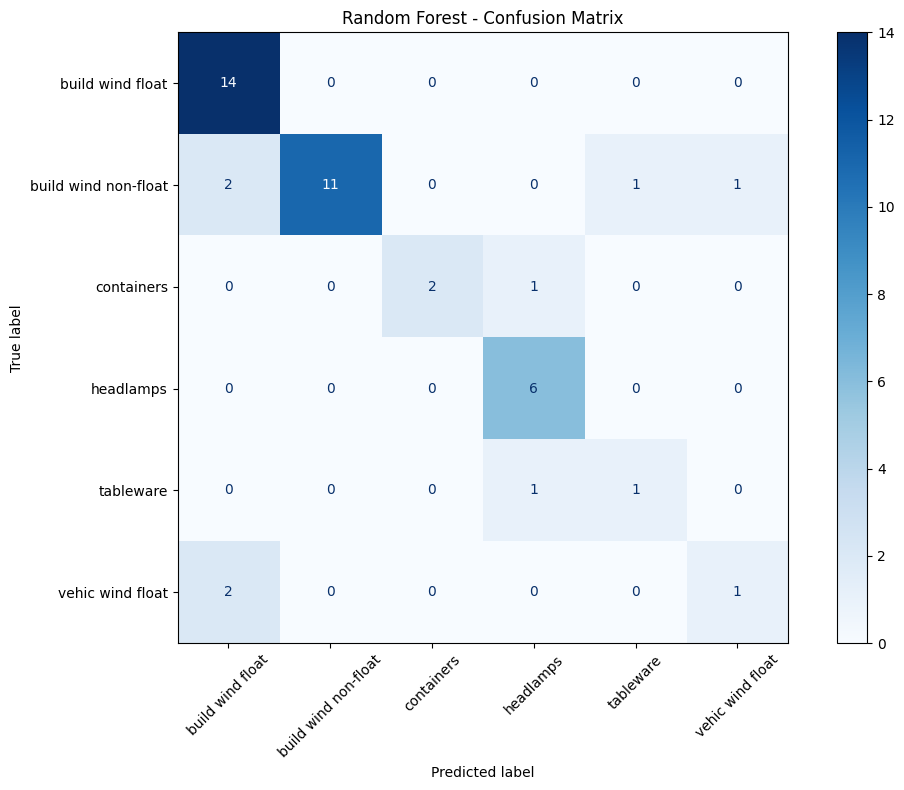

In [8]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Evaluate Random Forest model
print("Model Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(11, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


Feature Importance:


,Feature,Importance
2,Mg,0.162660
3,Al,0.152046
0,RI,0.140234
6,Ca,0.138928
1,Na,0.110953
4,Si,0.087784
7,Ba,0.083792
5,K,0.081405
8,Fe,0.042198


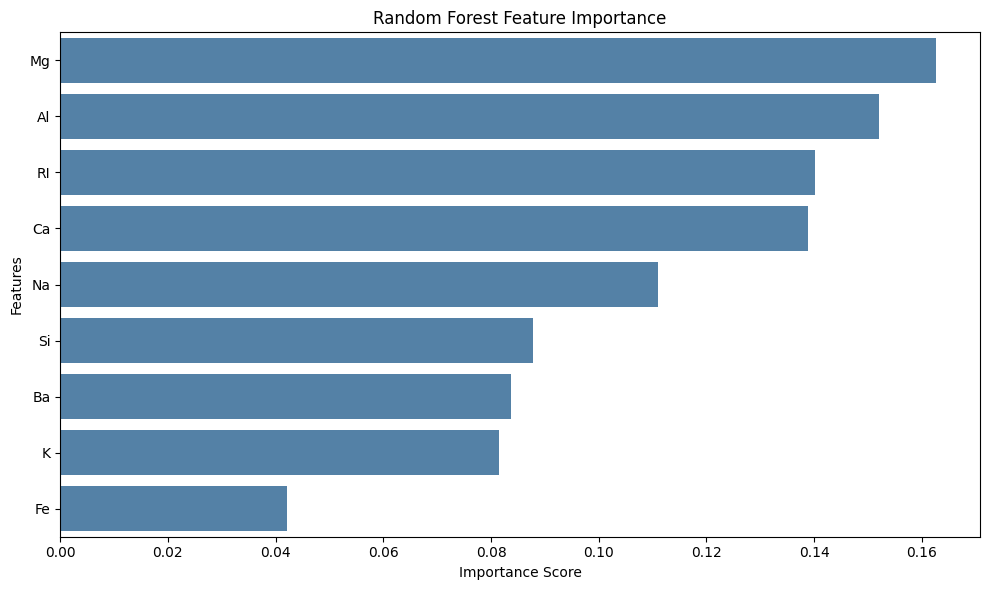

In [9]:

# Random Forest Feature Importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature Importance:")
display(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [10]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Define hyperparameter search space
param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

# Initialize Randomized Search
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

# Train and find best parameters
random_search.fit(X_train, y_train)

# Best model
best_rf = random_search.best_estimator_

# Predict test data
y_pred_tuned = best_rf.predict(X_test)

print("Best Parameters:", random_search.best_params_)
print("Best Cross-Validation Accuracy:",
      round(random_search.best_score_, 4))
print("Original Test Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))
print("Tuned Test Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))


Best Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}
Best Cross-Validation Accuracy: 0.7361
Original Test Accuracy: 0.814
Tuned Test Accuracy: 0.8605


,Model,Accuracy,F1-Score
0,Original Random Forest,0.8140,0.8066
1,Tuned Random Forest,0.8605,0.8517


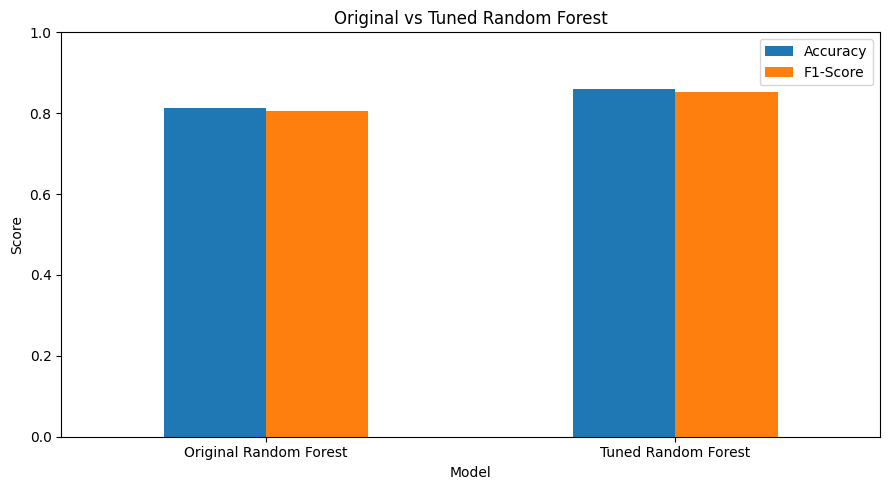

In [11]:

# Compare Original and Tuned Random Forest

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, y_pred_tuned, average="weighted")
    ]
})

display(comparison.round(4))

# Visualize model comparison
comparison.set_index("Model")[["Accuracy", "F1-Score"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Original vs Tuned Random Forest")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend()
plt.tight_layout()
plt.show()


## Conclusion

In this project, a Random Forest Classifier was implemented to predict glass types based on their chemical and physical properties.

The Glass Identification dataset contains 214 samples, 9 input features, and 6 glass categories.

The dataset was divided into 80% training data and 20% testing data using stratified sampling.

The original Random Forest model was trained using 100 decision trees and achieved:

- **Training Accuracy:** 100%
- **Testing Accuracy:** 81.4%
- **Weighted F1-Score:** Approximately 81%

Feature importance analysis showed that Magnesium (Mg), Aluminum (Al), and Refractive Index (RI) were the most influential features.

RandomizedSearchCV was used to optimize the model's hyperparameters through 5-fold cross-validation.

The original and tuned models were compared using Accuracy and Weighted F1-Score.

The results demonstrate that Random Forest can be used effectively for multiclass glass classification. However, the difference between training and testing accuracy suggests possible overfitting, while the performance on smaller classes indicates that class imbalance remains a challenge.

Overall, the project demonstrates the complete machine learning workflow, including data exploration, model training, evaluation, feature importance analysis, and hyperparameter tuning.